# Recommending recipes with Food.com data
**CSE 158 final project - Exploratory data analysis**

Can users' earlier reviews help us recommend recipes they may review later?
The central experiments ask **whether ingredient and tag preferences persist over time**
(Section 6) and **how much of a later recipe's content appears in a user's earlier reviews**
(Section 7). Supporting analyses examine ratings, popularity, available history, and recipes
with no previous reviews.

A review records neither confirmed cooking nor necessarily a positive experience.
Unreviewed user-recipe pairs are unknown, not known dislikes. Higher content overlap
suggests personalization potential; it does **not guarantee accurate recommendations**.

We use the full raw release and reproducible samples for preference experiments.
No predictive models or final train/test splits are created. Run all cells in order
with Python 3.12, pandas, NumPy, Matplotlib, and IPython; keep the two original CSVs
in `dataset/` beside this notebook.


In [1]:
from pathlib import Path
from collections import Counter
import ast
import hashlib
import importlib.metadata
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import display, Markdown

SEED = 158
DATA = Path('dataset')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True})
COLORS = ['#187E89', '#E59143', '#7776A6']
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

versions = {'Python': platform.python_version()}
for package in ['pandas', 'numpy', 'matplotlib', 'ipython']:
    versions[package] = importlib.metadata.version(package)
display(pd.Series(versions, name='version').to_frame())


,version
Python,3.12.8
pandas,3.0.1
numpy,2.2.6
matplotlib,3.10.0
ipython,9.1.0


## 1. What data and review history are available?

**Research question.** What does this release contain, and what needs checking before analysis?

**Analysis.** We use `RAW_recipes.csv` and `RAW_interactions.csv` from
[the original Food.com dataset, version 2](https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions),
collected for [Majumder et al. (2019)](https://aclanthology.org/D19-1613/).
The [authors' repository](https://github.com/majumderb/recipe-personalization) links to this release;
the [appendix](https://aclanthology.org/attachments/D19-1613.Attachment.pdf) reports
231,637 raw recipes and 1,132,367 reviews from 226,570 users. We use these raw files,
not the smaller processed dataset or its supplied splits.

Recipes include ingredients, tags, instructions, preparation time, nutrition, descriptions,
and submission dates. Reviews include user/recipe IDs, dates, ratings, and text.
The data does not record which recipes users saw without reviewing.
Checksums below verify that the files match previously checked downloads.


In [2]:
# Read-only checks: stop if either original dataset has changed.
FILES = {
    'RAW_recipes.csv': (294520189, '6a8136d1da9e03396a9f52d72200b3fddb8fe103f11e1496effca30ac4e0539f'),
    'RAW_interactions.csv': (349436524, '4e278d2f687b1020f5694e51003a7d6174344b51aebbdf4530de88b5c6a78ee4'),
}
for filename, (expected_bytes, expected_hash) in FILES.items():
    file_path = DATA / filename
    with file_path.open('rb') as stream:
        actual_hash = hashlib.file_digest(stream, 'sha256').hexdigest()
    assert file_path.stat().st_size == expected_bytes, filename
    assert actual_hash == expected_hash, filename
print('Both original CSV files verified; datasets are unchanged.')


Both original CSV files verified; datasets are unchanged.


In [3]:
raw_recipes = pd.read_csv(DATA / 'RAW_recipes.csv')
raw_reviews = pd.read_csv(DATA / 'RAW_interactions.csv')
assert raw_recipes.shape == (231637, 12)
assert raw_reviews.shape == (1132367, 5)
print(f'Loaded {len(raw_recipes):,} recipes (12 columns) and '
      f'{len(raw_reviews):,} reviews (5 columns).')

schema = pd.concat([
    pd.DataFrame({'table': name, 'column': frame.columns,
                  'missing rows': frame.isna().sum().values,
                  'Missing (%)': frame.isna().mean().values * 100})
    for name, frame in [('Recipes', raw_recipes), ('Reviews', raw_reviews)]
], ignore_index=True)
display(schema)


Loaded 231,637 recipes (12 columns) and 1,132,367 reviews (5 columns).


,table,column,missing rows,Missing (%)
0,Recipes,name,1,0.00
1,Recipes,id,0,0.00
2,Recipes,minutes,0,0.00
3,Recipes,contributor_id,0,0.00
4,Recipes,submitted,0,0.00
5,Recipes,tags,0,0.00
6,Recipes,nutrition,0,0.00
7,Recipes,n_steps,0,0.00
8,Recipes,steps,0,0.00
9,Recipes,description,4979,2.15


### Data preparation

- Keep every review, including rating `0`, which we treat as unspecified when summarizing
  1-5-star ratings. Missing descriptions or review text do not remove a recipe or review.
- Parse ingredient/tag lists, normalize case and spaces, and remove repeated entries
  within a recipe. Keep phrases such as `olive oil` intact.
- Keep reviews dated before recipe submission in overall summaries, but exclude them
  from time-based analyses. Dates provide days, not within-day ordering.
- Flag unusual preparation times and counts without discarding recipes or short histories.

The audit displays checks with issues. Assertions also verify unique user-recipe pairs,
valid IDs/ratings/dates, and recipe metadata for every review.


In [4]:
recipes = raw_recipes.drop(columns=['steps', 'nutrition', 'description']).copy()
reviews = raw_reviews.drop(columns='review').copy()
recipe_description_missing = raw_recipes.description.fillna('').str.strip().eq('')
review_text_missing = raw_reviews.review.fillna('').str.strip().eq('')
audit = {
    'Duplicate recipe rows': int(raw_recipes.duplicated().sum()),
    'Duplicate review rows': int(raw_reviews.duplicated().sum()),
    'Duplicate recipe IDs': int(recipes.id.duplicated().sum()),
    'Repeated user-recipe pairs': int(reviews.duplicated(['user_id', 'recipe_id']).sum()),
    'Missing recipe IDs': int(recipes.id.isna().sum()),
    'Missing review keys': int(reviews[['user_id', 'recipe_id']].isna().any(axis=1).sum()),
}
for frame, column in [(recipes, 'submitted'), (reviews, 'date')]:
    frame[column] = pd.to_datetime(frame[column], format='%Y-%m-%d', errors='coerce')
    audit[f'Invalid {column} dates'] = int(frame[column].isna().sum())

def parse_tokens(value):
    if not isinstance(value, str):
        return None
    try:
        parsed = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return None
    if not isinstance(parsed, list) or not all(isinstance(x, str) for x in parsed):
        return None
    return frozenset(' '.join(x.lower().split()) for x in parsed if x.strip())

for column in ['ingredients', 'tags']:
    parsed = recipes[column].map(parse_tokens)
    audit[f'Unparseable {column} lists'] = int(parsed.isna().sum())
    audit[f'Empty valid {column} lists'] = int(parsed.map(lambda x: x == frozenset()).sum())
    recipes[column + '_set'] = parsed.map(lambda x: x if x is not None else frozenset())
    recipes[column + '_available'] = parsed.notna() & parsed.map(bool)
    recipes = recipes.drop(columns=column)

audit['Review linked to unknown recipe'] = int((~reviews.recipe_id.isin(recipes.id)).sum())
audit['Ratings outside {0,1,2,3,4,5}'] = int((~reviews.rating.isin(range(6))).sum())
reviews['star_rating'] = reviews.rating.where(reviews.rating.between(1, 5))
submission = reviews.recipe_id.map(recipes.set_index('id').submitted)
before_submission = reviews.date < submission
audit['Review before recipe submission'] = int(before_submission.sum())
audit['Nonpositive preparation minutes'] = int(recipes.minutes.le(0).sum())
audit['Preparation minutes above one week'] = int(recipes.minutes.gt(7 * 24 * 60).sum())
audit['Nonpositive declared step counts'] = int(recipes.n_steps.le(0).sum())
audit['Nonpositive declared ingredient counts'] = int(recipes.n_ingredients.le(0).sum())
audit['Ingredient set size differs from declared count'] = int(
    recipes.ingredients_set.map(len).ne(recipes.n_ingredients).sum())
audit_table = pd.Series(audit, name='rows')
display(audit_table[audit_table.gt(0)].to_frame())

# Stop rather than silently changing rows if the release is inconsistent.
assert audit['Duplicate recipe rows'] == audit['Duplicate review rows'] == 0
assert recipes.id.is_unique and recipes.id.notna().all()
assert recipes.submitted.notna().all()
assert reviews[['user_id', 'recipe_id', 'date']].notna().all().all()
assert audit['Review linked to unknown recipe'] == 0
assert audit['Ratings outside {0,1,2,3,4,5}'] == 0
assert audit['Repeated user-recipe pairs'] == 0
temporal = reviews.loc[~before_submission].copy()
assert len(reviews) == len(temporal) + before_submission.sum()
del raw_recipes, raw_reviews


,rows
Empty valid tags lists,109
Review before recipe submission,1246
Nonpositive preparation minutes,1094
Preparation minutes above one week,256
Nonpositive declared step counts,1


In [5]:
n_users = reviews.user_id.nunique()
n_recipes = len(recipes)
n_reviews = len(reviews)
pair_density = n_reviews / (n_users * n_recipes)
display(pd.DataFrame({
    'start': [recipes.submitted.min(), reviews.date.min()],
    'end': [recipes.submitted.max(), reviews.date.max()],
}, index=['Recipe submissions', 'Reviews']))
display(Markdown(f"""**Results.** The release contains **{n_recipes:,} recipes**, **{n_users:,} users**,
and **{n_reviews:,} reviews**. Only **{pair_density:.4%} of possible user-recipe pairs**
have a review. Descriptions are missing or blank for **{recipe_description_missing.mean():.2%}**
of recipes; review text is missing for **{review_text_missing.mean():.3%}** of reviews.
Excluding **{before_submission.sum():,} reviews ({before_submission.mean():.2%})** dated
before recipe submission leaves **{len(temporal):,} reviews** for time-based analyses.

**Implications for our recommendation system.** Shared review histories are extremely
sparse. Recipe content may provide additional evidence, while unreviewed pairs remain unknown."""))


,start,end
Recipe submissions,1999-08-06,2018-12-04
Reviews,2000-01-25,2018-12-20


**Results.** The release contains **231,637 recipes**, **226,570 users**,
and **1,132,367 reviews**. Only **0.0022% of possible user-recipe pairs**
have a review. Descriptions are missing or blank for **2.15%**
of recipes; review text is missing for **0.015%** of reviews.
Excluding **1,246 reviews (0.11%)** dated
before recipe submission leaves **1,131,121 reviews** for time-based analyses.

**Implications for our recommendation system.** Shared review histories are extremely
sparse. Recipe content may provide additional evidence, while unreviewed pairs remain unknown.

## 2. How informative are the star ratings?

**Research question.** Do observed ratings provide much distinction between reviewed recipes?

**Analysis.** Show all stored values, then summarize 1-5-star ratings separately from
unspecified zeros. These ratings describe only people who chose to review a recipe.


,reviews,Share of reviews (%)
stored rating,,
0,60847,5.37
1,12818,1.13
2,14123,1.25
3,40855,3.61
4,187360,16.55
5,816364,72.09


,1-5-star ratings
count,"1,071,520.00"
mean,4.66
std,0.72
min,1.00
25%,5.00
50%,5.00
75%,5.00
max,5.00


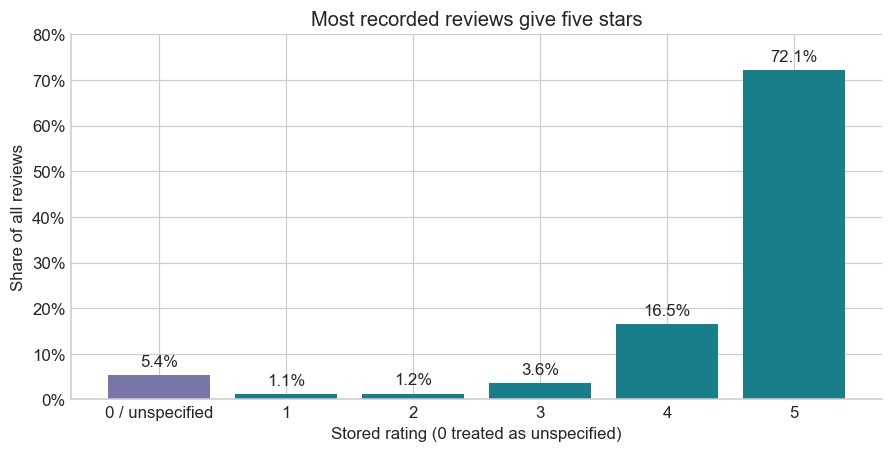

**Results.** Among specified ratings, **76.2% are five stars** and
**93.7% are four or five stars**. Zeros account for
**5.37% of all reviews**.

**Implications for our recommendation system.** The strong concentration at high ratings
motivates focusing on which recipes a user may review later. It does not show that rating
prediction is impossible. Ratings could help distinguish positive and negative experiences;
a recorded review alone does not mean the user liked the recipe.

In [6]:
rating_counts = reviews.rating.value_counts().reindex(range(6), fill_value=0).sort_index()
rating_summary = pd.DataFrame({'reviews': rating_counts,
                               'Share of reviews (%)': rating_counts / n_reviews * 100})
rating_summary.index.name = 'stored rating'
display(rating_summary)
stars = reviews.star_rating.dropna()
display(stars.describe().to_frame('1-5-star ratings'))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['0 / unspecified', '1', '2', '3', '4', '5'], rating_counts / n_reviews,
              color=[COLORS[2]] + [COLORS[0]] * 5)
ax.bar_label(bars, labels=[f'{v / n_reviews:.1%}' for v in rating_counts], padding=4)
ax.set(xlabel='Stored rating (0 treated as unspecified)', ylabel='Share of all reviews',
       title='Most recorded reviews give five stars', ylim=(0, .8))
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

five_share = stars.eq(5).mean()
high_share = stars.ge(4).mean()
display(Markdown(f"""**Results.** Among specified ratings, **{five_share:.1%} are five stars** and
**{high_share:.1%} are four or five stars**. Zeros account for
**{reviews.rating.eq(0).mean():.2%} of all reviews**.

**Implications for our recommendation system.** The strong concentration at high ratings
motivates focusing on which recipes a user may review later. It does not show that rating
prediction is impossible. Ratings could help distinguish positive and negative experiences;
a recorded review alone does not mean the user liked the recipe."""))


## 3. How much does recipe popularity explain?

**Research question.** Are reviews concentrated among a small share of recipes?

**Analysis.** Count reviewers per recipe across the entire released catalog and calculate
the share of reviews received by the most reviewed recipes. Unique user-recipe pairs
make reviewer counts equal review counts.


,Most reviewed recipes (% of catalog),recipes,Share of reviews (%)
0,0.10,232,7.91
1,1.00,2317,23.37
2,5.00,11582,43.11
3,10.00,23164,54.76
4,20.00,46328,68.46


,Reviews per recipe
quantile,
0.50,2.00
0.90,9.00
0.99,47.00


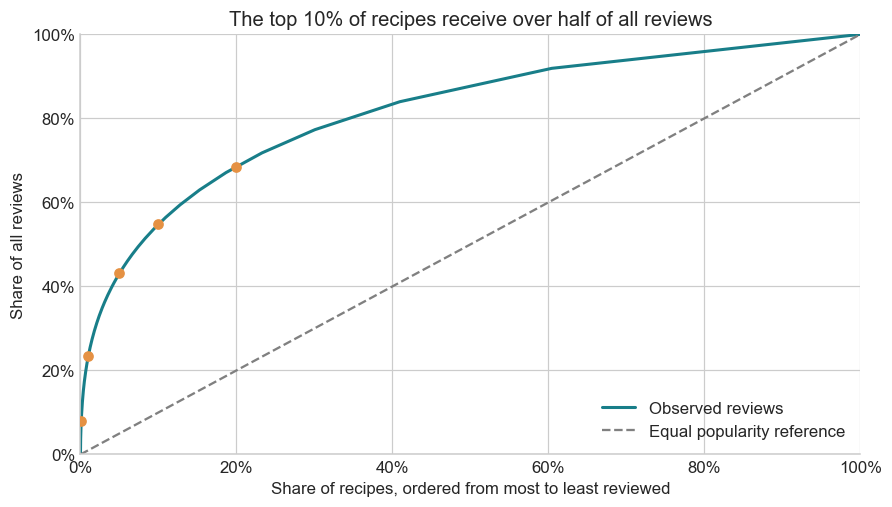

**Results.** The most reviewed **10% of recipes receive 54.8% of reviews**.
The median recipe has **2 reviews**, and
**39.7%** have exactly one. Every recipe has at least one
review somewhere in the raw snapshot; this does not mean every recipe had reviews at an earlier date.

**Implications for our recommendation system.** Popularity is a useful baseline for users
with little history. A shared ranking can overlook personal preferences and rarely reviewed
recipes. Calculate popularity from earlier reviews only when evaluating recommendations.

In [7]:
recipe_counts = reviews.groupby('recipe_id').size().reindex(recipes.id, fill_value=0)
recipe_counts.index.name = 'recipe_id'
ranked_counts = recipe_counts.sort_values(ascending=False)
cumulative_reviews = ranked_counts.cumsum().to_numpy() / n_reviews
fractions = [0.001, 0.01, 0.05, 0.10, 0.20]
concentration = pd.DataFrame([
    {'Most reviewed recipes (% of catalog)': fraction * 100,
     'recipes': int(np.ceil(fraction * n_recipes)),
     'Share of reviews (%)': cumulative_reviews[int(np.ceil(fraction * n_recipes)) - 1] * 100}
    for fraction in fractions
])
display(concentration)
display(recipe_counts.quantile([.5, .9, .99]).rename_axis('quantile').to_frame('Reviews per recipe'))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.r_[0, np.arange(1, n_recipes + 1) / n_recipes],
        np.r_[0, cumulative_reviews], color=COLORS[0], linewidth=2, label='Observed reviews')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Equal popularity reference')
ax.scatter(concentration['Most reviewed recipes (% of catalog)'] / 100,
           concentration['Share of reviews (%)'] / 100, color=COLORS[1], zorder=3)
ax.set(xlabel='Share of recipes, ordered from most to least reviewed',
       ylabel='Share of all reviews', title='The top 10% of recipes receive over half of all reviews',
       xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='lower right')
plt.show()

top10_share = concentration.loc[concentration['Most reviewed recipes (% of catalog)'].eq(10), 'Share of reviews (%)'].iloc[0] / 100
display(Markdown(f"""**Results.** The most reviewed **10% of recipes receive {top10_share:.1%} of reviews**.
The median recipe has **{recipe_counts.median():.0f} reviews**, and
**{recipe_counts.eq(1).mean():.1%}** have exactly one. Every recipe has at least one
review somewhere in the raw snapshot; this does not mean every recipe had reviews at an earlier date.

**Implications for our recommendation system.** Popularity is a useful baseline for users
with little history. A shared ranking can overlook personal preferences and rarely reviewed
recipes. Calculate popularity from earlier reviews only when evaluating recommendations."""))


## 4. Which users have enough review history?

**Research question.** How much evidence is available for personalization across users?

**Analysis.** Count distinct recipes reviewed per user. Compare each history group's
share of users with its share of reviews, and measure the time between repeat reviewers'
first and last reviews. These are full-record counts, not history available at an earlier date.


,Users,Reviews
band,,
1,166256,166256
2-4,37228,94090
5-9,10600,68683
10-19,5799,77830
20-49,3932,118642
50+,2755,606866


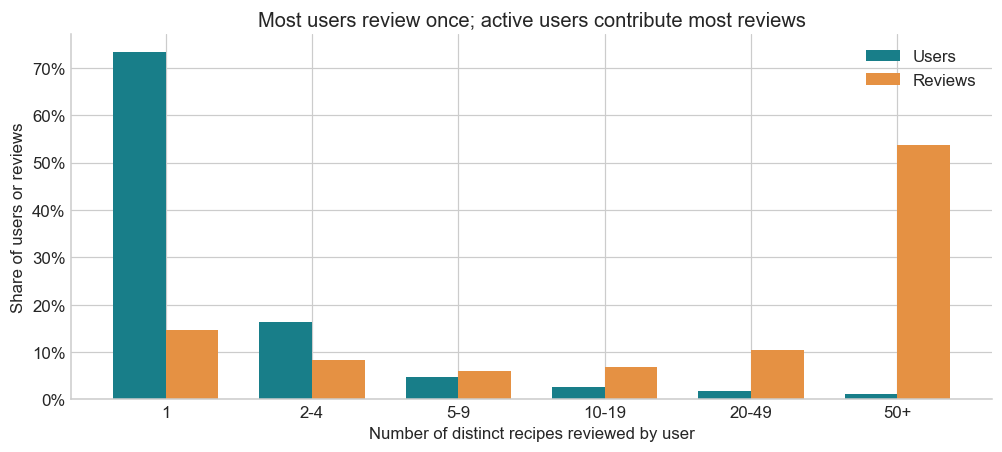

**Results.** **73.4% of users have one review**. Users with at least
five reviews make up **10.2% of users** but contribute
**77.0% of reviews**. Repeat reviewers have a median
**432 days** between first and last review.

**Implications for our recommendation system.** Collaborative filtering has more evidence
for active users than for short histories. A **new user** has no previous reviews;
a user with some reviews may still have **insufficient history** for a particular method.
The following pair experiments require at least two reviews, while historical coverage
requires twenty strictly earlier reviews. Neither threshold guarantees useful personalization.

In [8]:
user_counts = reviews.groupby('user_id').recipe_id.nunique()
bands = ['1', '2-4', '5-9', '10-19', '20-49', '50+']
user_bands = pd.cut(user_counts, bins=[0, 1, 4, 9, 19, 49, np.inf], labels=bands)
user_behavior = pd.DataFrame({'history': user_counts, 'band': user_bands})
history_table = user_behavior.groupby('band', observed=False).agg(
    users=('history', 'size'), reviews=('history', 'sum'))
history_table['user share %'] = history_table.users / n_users * 100
history_table['review share %'] = history_table.reviews / n_reviews * 100
display(history_table[['users', 'reviews']].rename(columns={'users': 'Users', 'reviews': 'Reviews'}))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(bands))
ax.bar(x - .18, history_table['user share %'] / 100, .36, label='Users', color=COLORS[0])
ax.bar(x + .18, history_table['review share %'] / 100, .36, label='Reviews', color=COLORS[1])
ax.set(xticks=x, xticklabels=bands, xlabel='Number of distinct recipes reviewed by user',
       ylabel='Share of users or reviews', title='Most users review once; active users contribute most reviews')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

user_dates = reviews.groupby('user_id').date.agg(['min', 'max'])
user_dates['span_days'] = (user_dates['max'] - user_dates['min']).dt.days
repeat_spans = user_dates.loc[user_counts.ge(2), 'span_days']
single_user_share = user_counts.eq(1).mean()
active_review_share = user_counts.loc[user_counts.ge(5)].sum() / n_reviews
display(Markdown(f"""**Results.** **{single_user_share:.1%} of users have one review**. Users with at least
five reviews make up **{user_counts.ge(5).mean():.1%} of users** but contribute
**{active_review_share:.1%} of reviews**. Repeat reviewers have a median
**{repeat_spans.median():,.0f} days** between first and last review.

**Implications for our recommendation system.** Collaborative filtering has more evidence
for active users than for short histories. A **new user** has no previous reviews;
a user with some reviews may still have **insufficient history** for a particular method.
The following pair experiments require at least two reviews, while historical coverage
requires twenty strictly earlier reviews. Neither threshold guarantees useful personalization."""))


## 5. Do the same user's recipes share more content?

**Research question.** Is there a content preference signal worth examining over time?

**Analysis.** Use **Jaccard overlap**: shared ingredients or tags divided by all distinct
entries in the two recipes. For readability, report it as a **score from 0 to 100**:
0 means no shared entries, 100 means identical sets; two empty sets score 0.
A difference of 2 score points means, for example, 10 versus 8, not a 2% relative gain.

With seed 158, sample **8,000 users with at least two reviews**, up to five distinct
recipe pairs per user, and average within users before giving each user equal weight.
Compare their recipes with:

- **Random catalog:** two different recipes sampled uniformly from the catalog.
- **Year-shuffled:** keep the earlier recipe and shuffle the later recipe among pairs
  with the same later-review year, ten times. This retains review-frequency patterns
  and broad time trends; identical-recipe pairs are excluded.

Repeat after removing tags found on at least **20% of recipes**. Report the same-user
minus year-shuffled difference with a 95% uncertainty interval from **1,000 user-level
bootstrap resamples**. Resampling users estimates uncertainty in the average, not the
accuracy of future recommendations. This full-history comparison provides context for
the two central time-based experiments.


In [9]:
ingredient_frequency = Counter(token for values in recipes.ingredients_set for token in values)
tag_frequency = Counter(token for values in recipes.tags_set for token in values)
broad_tags = {token for token, count in tag_frequency.items() if count / n_recipes >= .20}
recipes['specific_tags_set'] = recipes.tags_set.map(lambda values: values - broad_tags)
content_sets = {
    'Ingredients': recipes.ingredients_set.to_numpy(),
    'All tags': recipes.tags_set.to_numpy(),
    'Tags below 20% prevalence': recipes.specific_tags_set.to_numpy(),
}
recipe_position = pd.Series(np.arange(n_recipes), index=recipes.id)
pair_rng = np.random.default_rng(SEED)
eligible = user_counts.index[user_counts.ge(2)].to_numpy()
sampled_users = np.sort(pair_rng.choice(eligible, size=min(8000, len(eligible)), replace=False))
sample_history = reviews.loc[reviews.user_id.isin(sampled_users), ['user_id', 'recipe_id', 'date']]
pair_records = []
for user_id, history in sample_history.groupby('user_id', sort=True):
    positions = recipe_position.loc[history.recipe_id].to_numpy()
    years = history.date.dt.year.to_numpy()
    n = len(history)
    target = min(5, n * (n - 1) // 2)
    chosen = set()
    while len(chosen) < target:
        a, b = sorted(pair_rng.choice(n, 2, replace=False))
        chosen.add((a, b))
    for a, b in sorted(chosen):
        # Orient by review time; the second endpoint supplies the matching year.
        if history.date.iloc[a] > history.date.iloc[b]:
            a, b = b, a
        pair_records.append((user_id, positions[a], positions[b], years[b]))
pairs = pd.DataFrame(pair_records, columns=['user_id', 'a', 'b', 'year'])
pair_users = np.sort(pairs.user_id.unique())

def per_user(values):
    # Average pairs within each user before averaging across users.
    scores = pd.DataFrame({'user_id': pairs.user_id, 'similarity': values})
    return scores.groupby('user_id').similarity.mean().to_numpy()

def jaccards(sets, left, right):
    scores = []
    for a, b in zip(left, right):
        union = sets[a] | sets[b]
        scores.append(len(sets[a] & sets[b]) / len(union) if union else 0.0)
    return np.array(scores)

left, right = pairs.a.to_numpy(), pairs.b.to_numpy()
uniform_left = pair_rng.integers(n_recipes, size=len(pairs))
uniform_right = pair_rng.integers(n_recipes, size=len(pairs))
same = uniform_left == uniform_right
while same.any():
    uniform_right[same] = pair_rng.integers(n_recipes, size=same.sum())
    same = uniform_left == uniform_right

similarity_users = {}
for feature, sets in content_sets.items():
    similarity_users[feature] = {
        'Same user': per_user(jaccards(sets, left, right)),
        'Uniform catalog': per_user(jaccards(sets, uniform_left, uniform_right)),
    }


In [10]:
# Shuffle the later recipe within its review year, preserving recipe frequencies.
year_groups = list(pairs.groupby('year').indices.values())
null_sums = {feature: np.zeros(len(pairs)) for feature in content_sets}
null_counts = np.zeros(len(pairs), dtype=int)
excluded_null_pairs = 0
for _ in range(10):
    shuffled = right.copy()
    for indexes in year_groups:
        shuffled[indexes] = pair_rng.permutation(right[indexes])
    valid = left != shuffled
    excluded_null_pairs += int((~valid).sum())
    null_counts += valid
    for feature, sets in content_sets.items():
        null_sums[feature][valid] += jaccards(sets, left[valid], shuffled[valid])
assert (null_counts > 0).all()
for feature in content_sets:
    similarity_users[feature]['Year-shuffled'] = per_user(null_sums[feature] / null_counts)


In [11]:
# User-level paired bootstrap, in small batches to keep memory modest.
def bootstrap_mean_ci(values, seed=SEED, repeats=1000):
    rng = np.random.default_rng(seed)
    means = []
    for start in range(0, repeats, 100):
        indexes = rng.integers(len(values), size=(min(100, repeats-start), len(values)))
        means.extend(values[indexes].mean(axis=1))
    return np.percentile(means, [2.5, 97.5])

similarity_rows = []
for feature, conditions in similarity_users.items():
    difference = conditions['Same user'] - conditions['Year-shuffled']
    low, high = bootstrap_mean_ci(difference)
    similarity_rows.append({
        'content': feature, **{key: value.mean() for key, value in conditions.items()},
        'paired difference': difference.mean(), '95% CI low': low, '95% CI high': high,
    })
similarity_table = pd.DataFrame(similarity_rows).set_index('content')
similarity_display = similarity_table[['Same user', 'Uniform catalog', 'Year-shuffled']].mul(100)
similarity_display['Extra score points [95% interval]'] = [
    f"{row['paired difference'] * 100:.2f} [{row['95% CI low'] * 100:.2f}, {row['95% CI high'] * 100:.2f}]"
    for _, row in similarity_table.iterrows()
]
display(similarity_display.rename(columns={'Uniform catalog': 'Random catalog'})
        .rename(index={'Tags below 20% prevalence': 'Less common tags'})
        .style.format({column: '{:.2f}' for column in ['Same user', 'Random catalog', 'Year-shuffled']}))
print(f'{len(sampled_users):,} of {len(eligible):,} eligible users; {len(pairs):,} recipe pairs.')
print(f'Excluded {excluded_null_pairs:,} identical-recipe pairs across 10 year shuffles.')
print(f'Tag comparison repeated after removing {len(broad_tags)} common tags (on at least 20% of recipes).')


,Same user,Random catalog,Year-shuffled,Extra score points [95% interval]
content,,,,
Ingredients,5.27,2.84,3.87,"1.40 [1.26, 1.54]"
All tags,24.75,21.30,22.26,"2.49 [2.31, 2.65]"
Less common tags,7.68,4.47,5.07,"2.61 [2.42, 2.78]"


8,000 of 60,314 eligible users; 25,858 recipe pairs.
Excluded 74 identical-recipe pairs across 10 year shuffles.
Tag comparison repeated after removing 19 common tags (on at least 20% of recipes).


In [12]:
# Check whether the pattern appears across different history lengths.
sample_counts = user_counts.reindex(pair_users).to_numpy()
strata = pd.cut(sample_counts, [1, 4, 19, np.inf], labels=['2-4', '5-19', '20+'])
user_gaps = pd.DataFrame({'history': strata})
for label, feature in [('Ingredient gap', 'Ingredients'),
                       ('Less-common-tag gap', 'Tags below 20% prevalence')]:
    conditions = similarity_users[feature]
    user_gaps[label] = conditions['Same user'] - conditions['Year-shuffled']
stratified = user_gaps.groupby('history', observed=True).agg(
    users=('Ingredient gap', 'size'), ingredient_gap=('Ingredient gap', 'mean'),
    tag_gap=('Less-common-tag gap', 'mean'))
stratified[['ingredient_gap', 'tag_gap']] *= 100
display(stratified.rename(columns={'users': 'Users', 'ingredient_gap': 'Extra ingredient score points',
                                   'tag_gap': 'Extra less-common-tag score points'})
        .rename_axis('Reviews per user'))

ingredient_result = similarity_table.loc['Ingredients']
specific_result = similarity_table.loc['Tags below 20% prevalence']
display(Markdown(f"""**Results.** Same-user recipes have an ingredient overlap score of
**{ingredient_result['Same user'] * 100:.2f}**, compared with
**{ingredient_result['Uniform catalog'] * 100:.2f}** for random catalog recipes and
**{ingredient_result['Year-shuffled'] * 100:.2f}** after year shuffling.
The extra **{ingredient_result['paired difference'] * 100:.2f} score points** is small,
although its 95% interval is above zero. Less common tags also retain extra overlap
(**{specific_result['paired difference'] * 100:.2f} score points**). Both differences
are positive in every history group and smaller among more active reviewers.

**Implications for our recommendation system.** Content offers a modest personalization
signal among repeat reviewers, who represent **{len(eligible) / n_users:.1%} of users**.
Exposure to similar recipes and disliked reviews may also affect the result.
We next ask whether the signal persists and whether strictly earlier content helps
explain later recipe choices."""))


,Users,Extra ingredient score points,Extra less-common-tag score points
Reviews per user,,,
2-4,4855,1.80,3.27
5-19,2249,0.89,1.90
20+,896,0.46,0.84


**Results.** Same-user recipes have an ingredient overlap score of
**5.27**, compared with
**2.84** for random catalog recipes and
**3.87** after year shuffling.
The extra **1.40 score points** is small,
although its 95% interval is above zero. Less common tags also retain extra overlap
(**2.61 score points**). Both differences
are positive in every history group and smaller among more active reviewers.

**Implications for our recommendation system.** Content offers a modest personalization
signal among repeat reviewers, who represent **26.6% of users**.
Exposure to similar recipes and disliked reviews may also affect the result.
We next ask whether the signal persists and whether strictly earlier content helps
explain later recipe choices.

## 6. Do ingredient and tag preferences persist over time?

**Research question.** Do a user's recipes still share extra content when reviewed more
than a year apart, after accounting for timing and popularity?

**Analysis.** From date-consistent reviews, sample up to **8,000 repeat reviewers**
(seed 159). Sample uniformly up to **three distinct recipe pairs per user per interval**:
0-30, 31-90, 91-180, 181-365, and more than 365 days. Day 365 is in only the fourth group.
Both recipes must have ingredients and tags.

Keep the later recipe fixed. Replace the earlier recipe with reviews by up to five
**different users**, matching its review year, time-gap interval, and recipe popularity
on that earlier date. Popularity uses only reviews on earlier days, grouped as
0, 1, 2-4, 5-14, 15-49, or 50+ reviews. Sample donor users uniformly, then one eligible
recipe per donor; donors come from the sampled users. Exclude the focal user and recipes
identical to the later recipe. Remove pairs with no match from both comparisons.

Average pairs within each user and interval, then weight users equally. Shaded 95%
intervals use **1,000 user-level bootstrap resamples**. Report overlap on the same
0-100 scale as Section 5. Intervals can contain different users, so their differences
do not directly measure changes in one person's taste. Same-day reviews have no known order.


In [13]:
# Match on recipe popularity available before the earlier review day.
recipe_days = temporal.groupby(['recipe_id', 'date']).size().rename('day_reviews').reset_index()
recipe_days['prior_recipe_reviews'] = (
    recipe_days.groupby('recipe_id').day_reviews.cumsum() - recipe_days.day_reviews
)
time_reviews = temporal[['user_id', 'recipe_id', 'date']].merge(
    recipe_days[['recipe_id', 'date', 'prior_recipe_reviews']],
    on=['recipe_id', 'date'], validate='many_to_one'
)
time_reviews['position'] = recipe_position.reindex(time_reviews.recipe_id).to_numpy()
time_reviews['day'] = (time_reviews.date - pd.Timestamp('2000-01-01')).dt.days
time_reviews['year'] = time_reviews.date.dt.year
time_reviews['pop_band'] = pd.cut(
    time_reviews.prior_recipe_reviews, [-1, 0, 1, 4, 14, 49, np.inf], labels=False
).astype(int)
available_content = recipes[['ingredients_available', 'tags_available']].all(axis=1).to_numpy()
time_reviews['has_content'] = available_content[time_reviews.position]

TIME_FEATURES = {'Ingredients': content_sets['Ingredients'], 'Tags': content_sets['All tags']}
GAP_LABELS = ['0-30', '31-90', '91-180', '181-365', '>365']
GAP_LIMITS = [(0, 30), (31, 90), (91, 180), (181, 365), (366, None)]
lag_rng = np.random.default_rng(SEED + 1)
valid_user_counts = time_reviews.groupby('user_id').size()
lag_eligible = valid_user_counts.index[valid_user_counts.ge(2)].to_numpy()
lag_users = np.sort(lag_rng.choice(lag_eligible, min(8000, len(lag_eligible)), replace=False))
lag_history = time_reviews.loc[time_reviews.user_id.isin(lag_users)].sort_values(['date', 'recipe_id'])

# Count partners for each first recipe, then sample pair numbers uniformly.
# This avoids a large n-by-n array for very active users.
def sample_time_pairs(days, lower_days, upper_days, rng, limit=3):
    lower = np.maximum(np.searchsorted(days, days + lower_days), np.arange(len(days)) + 1)
    upper = (np.searchsorted(days, days + upper_days, side='right')
             if upper_days is not None else np.full(len(days), len(days)))
    counts = np.maximum(upper - lower, 0)
    cumulative = counts.cumsum()
    total = int(cumulative[-1])
    if total == 0:
        return []
    pair_numbers = np.sort(rng.choice(total, size=min(limit, total), replace=False))
    first = np.searchsorted(cumulative, pair_numbers, side='right')
    preceding = np.r_[0, cumulative[:-1]]
    second = lower[first] + pair_numbers - preceding[first]
    return list(zip(first, second))

lag_records = []
for user_id, history in lag_history.groupby('user_id', sort=True):
    history = history.loc[history.has_content]
    if len(history) < 2:
        continue
    days, positions = history.day.to_numpy(), history.position.to_numpy()
    years, pop_bands = history.year.to_numpy(), history.pop_band.to_numpy()
    for interval, (low, high) in zip(GAP_LABELS, GAP_LIMITS):
        for a, b in sample_time_pairs(days, low, high, lag_rng):
            lag_records.append((user_id, interval, positions[a], positions[b],
                                days[a], days[b], years[a], pop_bands[a]))
lag_pairs = pd.DataFrame(lag_records, columns=[
    'user_id', 'interval', 'a', 'b', 'a_day', 'b_day', 'a_year', 'a_pop'
])
lag_donors = {}
for key, group in lag_history.loc[lag_history.has_content].groupby(['year', 'pop_band']):
    lag_donors[key] = (group.day.to_numpy(), group.user_id.to_numpy(), group.position.to_numpy())
print(f'{len(lag_users):,} of {len(lag_eligible):,} repeat users sampled; '
      f'{len(lag_pairs):,} pairs sampled across five intervals.')


8,000 of 60,287 repeat users sampled; 46,013 pairs sampled across five intervals.


In [14]:
lag_results, lag_matched_counts = [], []
for row in lag_pairs.itertuples(index=False):
    low, high = GAP_LIMITS[GAP_LABELS.index(row.interval)]
    donor_days, donor_users, donor_recipes = lag_donors[(row.a_year, row.a_pop)]
    first = 0 if high is None else np.searchsorted(donor_days, row.b_day - high)
    last = np.searchsorted(donor_days, row.b_day - low, side='right')
    pool_users, pool_recipes = donor_users[first:last], donor_recipes[first:last]
    valid = (pool_users != row.user_id) & (pool_recipes != row.b)
    pool_users, pool_recipes = pool_users[valid], pool_recipes[valid]
    choices = np.unique(pool_users)
    if len(choices) == 0:
        continue
    donor_ids = lag_rng.choice(choices, size=min(5, len(choices)), replace=False)
    donor_positions = [lag_rng.choice(pool_recipes[pool_users == user]) for user in donor_ids]
    lag_matched_counts.append((row.user_id, row.interval, len(donor_ids)))
    for feature, sets in TIME_FEATURES.items():
        same_score = jaccards(sets, [row.a], [row.b])[0]
        random_score = jaccards(sets, donor_positions, [row.b] * len(donor_positions)).mean()
        lag_results.append((row.user_id, row.interval, feature, same_score, random_score))

lag_scores = pd.DataFrame(lag_results, columns=['user_id', 'interval', 'content', 'same', 'random'])
lag_user_scores = lag_scores.groupby(['user_id', 'interval', 'content'])[['same', 'random']].mean().reset_index()
lag_rows = []
for (interval, feature), group in lag_user_scores.groupby(['interval', 'content']):
    difference = (group.same - group.random).to_numpy()
    gap_low, gap_high = bootstrap_mean_ci(difference)
    same_ci, random_ci = bootstrap_mean_ci(group.same.to_numpy()), bootstrap_mean_ci(group.random.to_numpy())
    lag_rows.append({'interval': interval, 'content': feature, 'users': len(group),
                     'same': group.same.mean(), 'random': group.random.mean(),
                     'gap': difference.mean(), 'gap_low': gap_low, 'gap_high': gap_high,
                     'same_low': same_ci[0], 'same_high': same_ci[1],
                     'random_low': random_ci[0], 'random_high': random_ci[1]})
lag_summary = pd.DataFrame(lag_rows).set_index(['content', 'interval'])
lag_matches = pd.DataFrame(lag_matched_counts, columns=['user_id', 'interval', 'donors'])
lag_samples = lag_pairs.groupby('interval').agg(sampled_users=('user_id', 'nunique'), sampled_pairs=('a', 'size'))
lag_samples = lag_samples.join(lag_matches.groupby('interval').agg(
    matched_users=('user_id', 'nunique'), matched_pairs=('user_id', 'size'),
    mean_donors_per_pair=('donors', 'mean'))).reindex(GAP_LABELS)
lag_samples['matched_pairs_pct'] = lag_samples.matched_pairs / lag_samples.sampled_pairs * 100
display(lag_samples[['sampled_users', 'matched_users', 'sampled_pairs', 'matched_pairs',
                     'matched_pairs_pct', 'mean_donors_per_pair']].rename(columns={
    'sampled_users': 'Sampled users', 'matched_users': 'Matched users',
    'sampled_pairs': 'Sampled pairs', 'matched_pairs': 'Matched pairs',
    'matched_pairs_pct': 'Matched (%)', 'mean_donors_per_pair': 'Comparison users per pair',
}).rename_axis('Days between reviews'))
lag_display = lag_summary[['same', 'random', 'gap']].mul(100)
lag_display['Extra score points: 95% interval'] = [f'[{r.gap_low * 100:.2f}, {r.gap_high * 100:.2f}]' for r in lag_summary.itertuples()]
display(lag_display.reindex(pd.MultiIndex.from_product([TIME_FEATURES, GAP_LABELS], names=['content', 'interval']))
        .rename(columns={'same': 'Same user', 'random': 'Matched other users', 'gap': 'Extra score points'})
        .rename_axis(index=['Content', 'Days between reviews'])
        .style.format({'Same user': '{:.2f}', 'Matched other users': '{:.2f}', 'Extra score points': '{:.2f}'}))
assert lag_pairs.groupby(['user_id', 'interval']).size().le(3).all()
assert not lag_pairs.duplicated(['user_id', 'a', 'b']).any()
for interval, (low, high) in zip(GAP_LABELS, GAP_LIMITS):
    subset = lag_pairs.loc[lag_pairs.interval.eq(interval)]
    days = subset.b_day - subset.a_day
    assert days.ge(low).all() and (high is None or days.le(high).all())
print(f'{len(lag_matches):,}/{len(lag_pairs):,} pairs matched; '
      f'{lag_matches.user_id.nunique():,} users contribute at least one matched pair.')


,Sampled users,Matched users,Sampled pairs,Matched pairs,Matched (%),Comparison users per pair
Days between reviews,,,,,,
0-30,5315,5312,11449,11442,99.94,4.99
31-90,3387,3387,7942,7942,100.00,5.00
91-180,3178,3177,7603,7602,99.99,5.00
181-365,3438,3438,8383,8382,99.99,5.00
>365,4311,4311,10636,10636,100.00,5.00


46,004/46,013 pairs matched; 7,994 users contribute at least one matched pair.


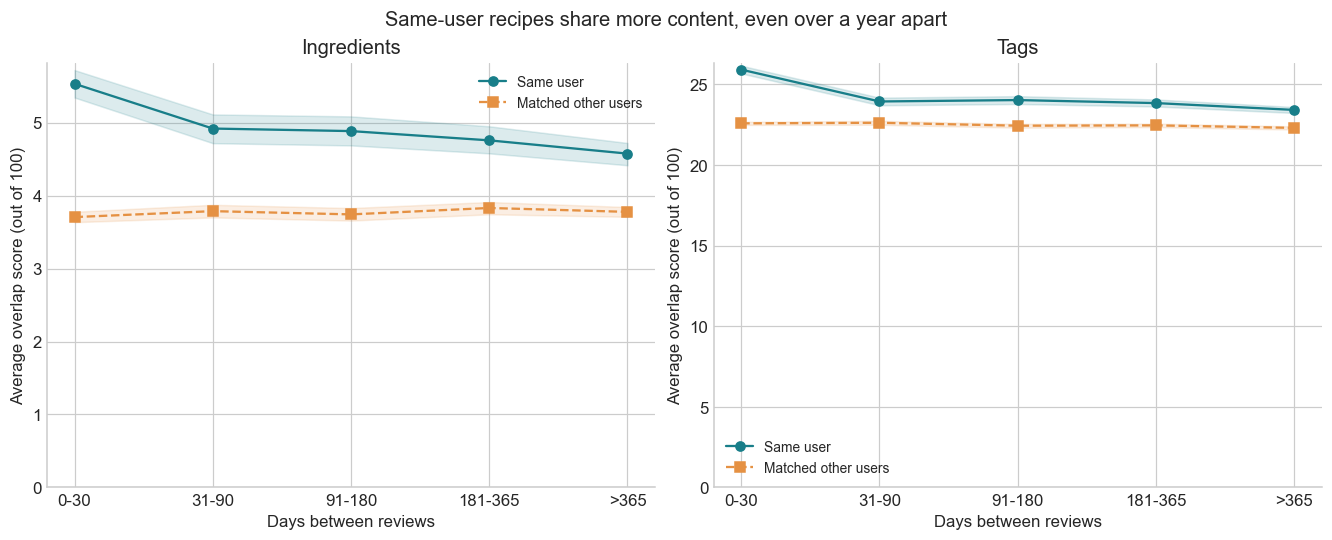

**Results.** For reviews more than a year apart, **4,311 users**
contribute matched pairs. Their ingredient overlap score averages
**4.57**, versus **3.78**
for matched other users: **0.80 extra score points**
(95% interval: **0.65 to 0.93**).
Tag scores are **23.41 versus 22.29**,
or **1.11 extra score points**.

Both ingredients and tags show extra overlap in every interval. The ingredient difference
beyond a year is smaller than the **1.83 points** at 0-30 days.
Different users contribute to each interval, so this does not establish individual preference decay.

**Implications for our recommendation system.** The small remaining difference is consistent
with lasting preferences and motivates comparing recent and longer histories in a content profile.
Persistence suggests personalization potential; it does not guarantee accurate recommendations
or establish that the differences are caused by taste.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, feature in zip(axes, TIME_FEATURES):
    results = lag_summary.loc[feature].reindex(GAP_LABELS)
    x = np.arange(len(GAP_LABELS))
    for condition, label, color, style in [
        ('same', 'Same user', COLORS[0], 'o-'),
        ('random', 'Matched other users', COLORS[1], 's--')
    ]:
        ax.plot(x, results[condition] * 100, style, color=color, label=label)
        ax.fill_between(x, results[condition + '_low'] * 100, results[condition + '_high'] * 100, color=color, alpha=.15)
    ax.set(title=feature, xticks=x, xticklabels=GAP_LABELS,
           xlabel='Days between reviews', ylabel='Average overlap score (out of 100)', ylim=(0, None))
    ax.legend(fontsize=9)
fig.suptitle('Same-user recipes share more content, even over a year apart')
plt.show()

long_ingredients = lag_summary.loc[('Ingredients', '>365')]
long_tags = lag_summary.loc[('Tags', '>365')]
short_ingredients = lag_summary.loc[('Ingredients', '0-30')]
display(Markdown(f"""**Results.** For reviews more than a year apart, **{int(long_ingredients.users):,} users**
contribute matched pairs. Their ingredient overlap score averages
**{long_ingredients.same * 100:.2f}**, versus **{long_ingredients.random * 100:.2f}**
for matched other users: **{long_ingredients.gap * 100:.2f} extra score points**
(95% interval: **{long_ingredients.gap_low * 100:.2f} to {long_ingredients.gap_high * 100:.2f}**).
Tag scores are **{long_tags.same * 100:.2f} versus {long_tags.random * 100:.2f}**,
or **{long_tags.gap * 100:.2f} extra score points**.

Both ingredients and tags show extra overlap in every interval. The ingredient difference
beyond a year is smaller than the **{short_ingredients.gap * 100:.2f} points** at 0-30 days.
Different users contribute to each interval, so this does not establish individual preference decay.

**Implications for our recommendation system.** The small remaining difference is consistent
with lasting preferences and motivates comparing recent and longer histories in a content profile.
Persistence suggests personalization potential; it does not guarantee accurate recommendations
or establish that the differences are caused by taste."""))


## 7. How much of a later recipe is covered by earlier reviews?

**Research question.** Do a user's earlier recipes cover more of a later recipe's
ingredients and tags than equally long histories from other users?

**Analysis.** **Historical coverage** is the share of a later recipe's entries found
in the combined ingredients or tags of earlier recipes. This differs from pair overlap:
several earlier recipes can collectively cover a later recipe even if each pair shares little.

With seed 160, sample up to **4,000 users** who have a later review after at least
**20 strictly earlier recipes**. Choose one eligible later review uniformly per user,
requiring both content fields. Compare the **5, 10, and 20 most recent recipes before
its review day**, using the same users and targets at every length. Exclude every target-day
review. Break older same-day ties by recipe ID to obtain exact lengths; missing earlier
content adds no entries.

For each target, sample up to **five different users uniformly** who already have twenty
earlier reviews on that date. Exclude the focal user and donors whose most recent twenty
include the target recipe. Use the same donors at every length and remove unmatched
targets from all lengths. Average donors, then give each focal user equal weight.
Shaded 95% intervals use **1,000 focal-user bootstrap resamples**.

This holds the target, calendar date, and history length fixed. It describes active users,
not users with short histories. Common ingredients and broad tags raise coverage for everyone;
**extra coverage over other users' histories** is the evidence for personalization.
Differences between coverage percentages are reported in **percentage points**:
50% versus 45% means 5 percentage points more coverage.


In [16]:
# Earlier reviews exclude every review on the target day.
user_days = time_reviews.groupby(['user_id', 'date']).size().rename('day_reviews').reset_index()
user_days['prior_user_reviews'] = user_days.groupby('user_id').day_reviews.cumsum() - user_days.day_reviews
coverage_reviews = time_reviews.merge(user_days[['user_id', 'date', 'prior_user_reviews']],
                                     on=['user_id', 'date'], validate='many_to_one')
coverage_candidates = coverage_reviews.loc[coverage_reviews.prior_user_reviews.ge(20) & coverage_reviews.has_content]
coverage_eligible = np.sort(coverage_candidates.user_id.unique())
coverage_rng = np.random.default_rng(SEED + 2)
coverage_users = np.sort(coverage_rng.choice(coverage_eligible, min(4000, len(coverage_eligible)), replace=False))
coverage_targets = []
for user_id, rows in coverage_candidates.loc[coverage_candidates.user_id.isin(coverage_users)].groupby('user_id'):
    target = rows.iloc[coverage_rng.integers(len(rows))]
    coverage_targets.append((user_id, int(target.position), int(target.day)))

# A donor user is sampled uniformly, not in proportion to their number of reviews.
coverage_donor_ids = valid_user_counts.index[valid_user_counts.ge(20)].to_numpy()
needed_users = np.union1d(coverage_donor_ids, coverage_users)
chronological = time_reviews.loc[time_reviews.user_id.isin(needed_users)].sort_values(['date', 'recipe_id'])
coverage_histories = {user_id: (rows.day.to_numpy(), rows.position.to_numpy())
                      for user_id, rows in chronological.groupby('user_id')}
donor_twentieth_day = np.array([coverage_histories[user][0][19] for user in coverage_donor_ids])
HISTORY_LENGTHS = [5, 10, 20]
coverage_records, coverage_match_counts = [], []
for user_id, target_position, target_day in coverage_targets:
    own_days, own_positions = coverage_histories[user_id]
    own_end = np.searchsorted(own_days, target_day)
    assert own_end >= 20 and own_days[own_end - 1] < target_day
    own_recent = own_positions[own_end - 20:own_end]
    assert target_position not in own_recent
    eligible_donors = coverage_donor_ids[(donor_twentieth_day < target_day) & (coverage_donor_ids != user_id)]
    donor_histories = []
    for donor_id in coverage_rng.permutation(eligible_donors):
        donor_days, donor_positions = coverage_histories[donor_id]
        donor_end = np.searchsorted(donor_days, target_day)
        recent = donor_positions[donor_end - 20:donor_end]
        assert donor_end >= 20 and donor_days[donor_end - 1] < target_day
        if target_position in recent:
            continue
        donor_histories.append(recent)
        if len(donor_histories) == 5:
            break
    if not donor_histories:
        continue
    coverage_match_counts.append((user_id, len(donor_histories), own_end))
    for length in HISTORY_LENGTHS:
        for feature, sets in TIME_FEATURES.items():
            target_set = sets[target_position]
            own_union = set().union(*(sets[position] for position in own_recent[-length:]))
            own_coverage = len(target_set & own_union) / len(target_set)
            random_coverages = []
            for history in donor_histories:
                donor_union = set().union(*(sets[position] for position in history[-length:]))
                random_coverages.append(len(target_set & donor_union) / len(target_set))
            coverage_records.append((user_id, length, feature, own_coverage, np.mean(random_coverages)))
coverage_scores = pd.DataFrame(coverage_records, columns=['user_id', 'length', 'content', 'same', 'random'])
coverage_matches = pd.DataFrame(coverage_match_counts, columns=['user_id', 'donors', 'available_history'])
coverage_rows = []
for (feature, length), group in coverage_scores.groupby(['content', 'length']):
    difference = (group.same - group.random).to_numpy()
    gap_ci = bootstrap_mean_ci(difference)
    same_ci, random_ci = bootstrap_mean_ci(group.same.to_numpy()), bootstrap_mean_ci(group.random.to_numpy())
    coverage_rows.append({'content': feature, 'length': length, 'users': len(group),
                         'same': group.same.mean(), 'random': group.random.mean(),
                         'gap': difference.mean(), 'gap_low': gap_ci[0], 'gap_high': gap_ci[1],
                         'same_low': same_ci[0], 'same_high': same_ci[1],
                         'random_low': random_ci[0], 'random_high': random_ci[1]})
coverage_summary = pd.DataFrame(coverage_rows).set_index(['content', 'length'])
coverage_display = coverage_summary[['users', 'same', 'random', 'gap']].copy()
coverage_display[['same', 'random', 'gap']] *= 100
coverage_display['Extra coverage: 95% interval (percentage points)'] = [f'[{r.gap_low * 100:.2f}, {r.gap_high * 100:.2f}]'
                                          for r in coverage_summary.itertuples()]
display(coverage_display.rename(columns={'users': 'Users', 'same': 'Own history (%)',
        'random': 'Histories from other users (%)', 'gap': 'Extra coverage (percentage points)'})
        .rename_axis(index=['Content', 'Earlier recipes']).style.format(precision=2, subset=[
            'Own history (%)', 'Histories from other users (%)', 'Extra coverage (percentage points)']))
print(f'{len(coverage_eligible):,} eligible users ({len(coverage_eligible) / n_users:.2%} of all users); '
      f'{len(coverage_users):,} sampled; {len(coverage_matches):,} matched targets.')
print(f'{len(coverage_donor_ids):,} potential donor users; '
      f'{coverage_matches.donors.mean():.2f} donors per target on average. '
      f'{len(coverage_users) - len(coverage_matches):,} targets had no eligible donor.')
assert coverage_scores.groupby(['content', 'length']).user_id.nunique().eq(len(coverage_matches)).all()
assert not coverage_scores.duplicated(['user_id', 'length', 'content']).any()
assert coverage_scores[['same', 'random']].ge(0).all().all()
assert coverage_scores[['same', 'random']].le(1).all().all()
# Nested histories cannot lose coverage as their length increases.
for condition in ['same', 'random']:
    by_length = coverage_scores.pivot(index=['user_id', 'content'], columns='length', values=condition)
    assert by_length.diff(axis=1).iloc[:, 1:].ge(-1e-12).all().all()


6,330 eligible users (2.79% of all users); 4,000 sampled; 4,000 matched targets.
6,686 potential donor users; 5.00 donors per target on average. 0 targets had no eligible donor.


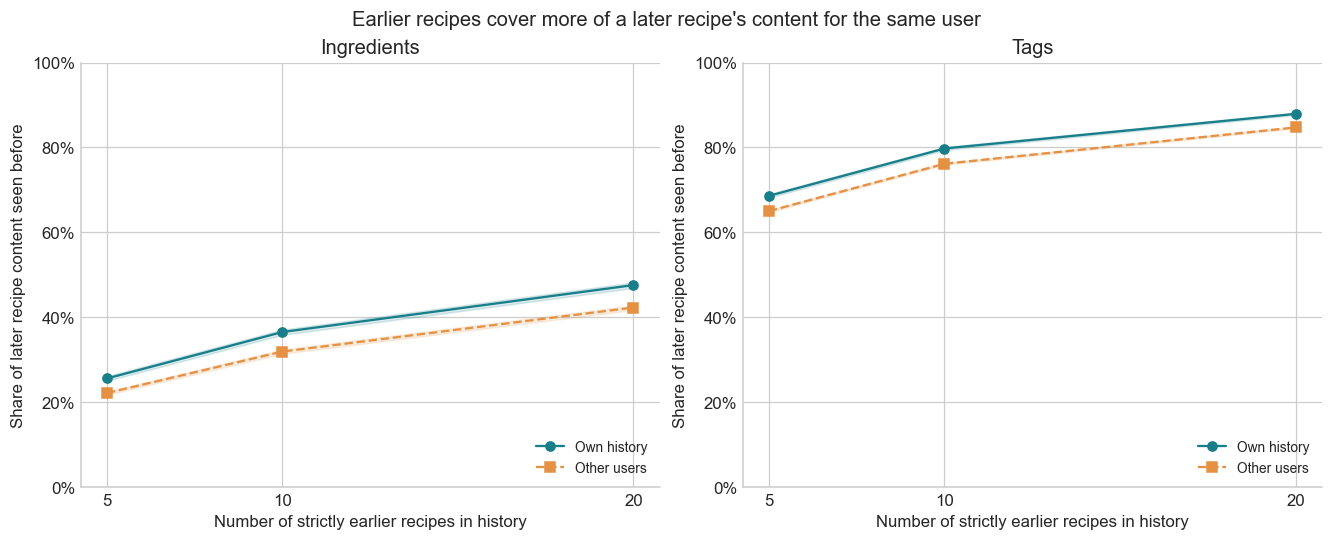

**Results.** With twenty earlier recipes, a user's history covers
**47.6% of later ingredients**, versus
**42.3%** for other users' histories. The difference is
**5.28 percentage points**
(95% interval: **4.82 to 5.75**).
In plain language, the user's own history covers about
**5.3 more of every 100 later ingredients**, on average.
Tag coverage is **87.9% versus 84.7%**,
a difference of **3.19 percentage points**.

Coverage rises with history length for both groups. The extra ingredient coverage grows
from **3.44 percentage points**
with five recipes to **5.28** with twenty. High tag coverage
also occurs for other users, reflecting shared labels. Even with twenty earlier recipes,
**52.4% of later ingredients remain unseen**, on average.

**Implications for our recommendation system.** Historical content could supplement
popularity and collaborative filtering, while allowing unfamiliar ingredients.
Higher coverage suggests personalization potential, **not guaranteed recommendation accuracy**:
we have not ranked recommendations or measured their quality. The eligible users make up only
**2.79% of all users**; these findings do not establish
the same benefit for short histories or for recipes with no previous reviews.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, feature in zip(axes, TIME_FEATURES):
    results = coverage_summary.loc[feature].reindex(HISTORY_LENGTHS)
    for condition, label, color, style in [
        ('same', 'Own history', COLORS[0], 'o-'),
        ('random', 'Other users', COLORS[1], 's--')
    ]:
        ax.plot(HISTORY_LENGTHS, results[condition], style, color=color, label=label)
        ax.fill_between(HISTORY_LENGTHS, results[condition + '_low'], results[condition + '_high'],
                        color=color, alpha=.15)
    ax.set(title=feature, xlabel='Number of strictly earlier recipes in history',
           ylabel='Share of later recipe content seen before', xticks=HISTORY_LENGTHS, ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=9, loc='lower right')
fig.suptitle("Earlier recipes cover more of a later recipe's content for the same user")
plt.show()

coverage_ingredients = coverage_summary.loc[('Ingredients', 20)]
coverage_tags = coverage_summary.loc[('Tags', 20)]
display(Markdown(f"""**Results.** With twenty earlier recipes, a user's history covers
**{coverage_ingredients.same:.1%} of later ingredients**, versus
**{coverage_ingredients.random:.1%}** for other users' histories. The difference is
**{coverage_ingredients.gap * 100:.2f} percentage points**
(95% interval: **{coverage_ingredients.gap_low * 100:.2f} to {coverage_ingredients.gap_high * 100:.2f}**).
In plain language, the user's own history covers about
**{coverage_ingredients.gap * 100:.1f} more of every 100 later ingredients**, on average.
Tag coverage is **{coverage_tags.same:.1%} versus {coverage_tags.random:.1%}**,
a difference of **{coverage_tags.gap * 100:.2f} percentage points**.

Coverage rises with history length for both groups. The extra ingredient coverage grows
from **{coverage_summary.loc[('Ingredients', 5), 'gap'] * 100:.2f} percentage points**
with five recipes to **{coverage_ingredients.gap * 100:.2f}** with twenty. High tag coverage
also occurs for other users, reflecting shared labels. Even with twenty earlier recipes,
**{1 - coverage_ingredients.same:.1%} of later ingredients remain unseen**, on average.

**Implications for our recommendation system.** Historical content could supplement
popularity and collaborative filtering, while allowing unfamiliar ingredients.
Higher coverage suggests personalization potential, **not guaranteed recommendation accuracy**:
we have not ranked recommendations or measured their quality. The eligible users make up only
**{len(coverage_eligible) / n_users:.2%} of all users**; these findings do not establish
the same benefit for short histories or for recipes with no previous reviews."""))


## 8. When do recipes have no previous reviews?

**Research question.** How often do reviews concern recipes with no prior review history,
and how is this different from a new recipe or a new user?

**Analysis.** Keep these cases separate:

- **New recipe:** newly submitted and available only from its submission date.
- **Recipe without previous reviews:** no recorded review before the reference date.
  It may be new or may have been published much earlier.
- **New user:** no review before the reference date. A previously seen user can still
  have too few reviews for personalization; merely being known is not enough.

Using date-consistent reviews, compare five diagnostic years without choosing a train/test split.
**No reviews before Jan 1** freezes history at the start of each year; split those reviews
between older recipes and recipes submitted that year. Later submissions enter the catalog
only when published. **On recipe's first review day** updates history daily; count all reviews
on that day because within-day order is unknown.

Table percentages use all reviews in each year, except the column for **known users** (previously seen users),
which uses only reviews by users observed before January 1. Measure content availability
once per distinct recipe without reviews before January 1.


,Reviews,No reviews before Jan 1 (%),First review day (%),Older unreviewed recipes (%),Published that year (%),No prior reviews: known users (%)
year,,,,,,
2005,65927,45.13,27.66,16.34,28.79,45.96
2008,167265,33.29,20.89,14.42,18.87,36.04
2011,72140,23.84,18.47,14.41,9.43,26.75
2014,30503,17.40,13.15,11.88,5.52,19.43
2017,27062,5.88,5.08,4.72,1.17,9.24


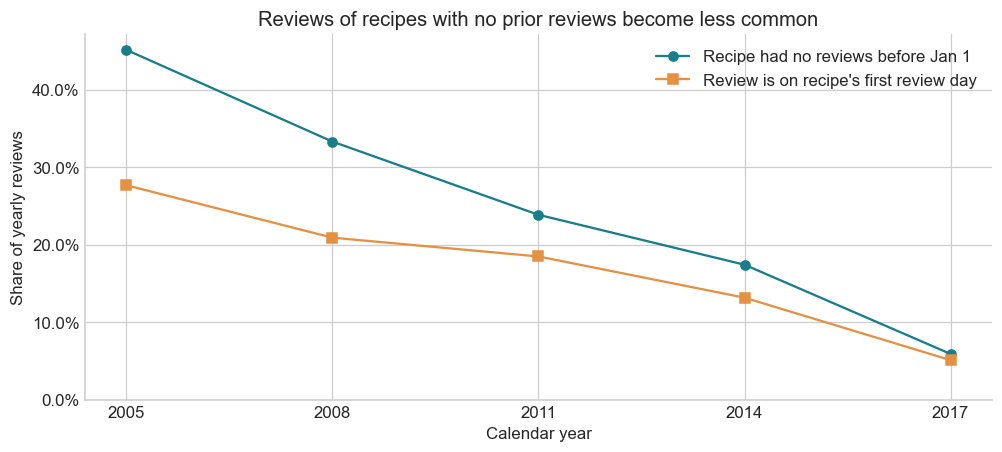

**Results.** Across the valid timeline, **20.8% of reviews** occur
on a recipe's first review day and **21.6%** on a user's first
review day. These totals include the start of observation; the yearly results show
that recipes without reviews remain relevant later.

In 2017, **5.9% of reviews** concern
recipes with no reviews before January 1: **4.7%**
concern already published recipes and **1.2%**
concern recipes submitted during 2017. Among previously seen users,
**9.2%** of reviews
concern recipes without reviews before January 1.

At least **99.72%** of distinct
recipes without January 1 reviews have both content fields in each diagnostic year.
After removing conflicting dates, **136 recipes** have no valid reviews.
Every recipe has a raw review somewhere in this release, so these percentages describe
observed reviews, not the full catalog of recipes a live system might encounter.

**Implications for our recommendation system.** Review-based collaborative filtering
lacks item history for recipes without prior reviews, including older unreviewed recipes.
Content offers features for those recipes, but a user's own content profile still needs
review history. New or insufficient-history users need a fallback such as popularity.

In [18]:
first_recipe_day = temporal.groupby('recipe_id').date.min()
first_user_day = temporal.groupby('user_id').date.min()
temporal['recipe_first_day'] = temporal.recipe_id.map(first_recipe_day)
temporal['no_earlier_recipe_day'] = temporal.date.eq(temporal.recipe_first_day)
temporal['no_earlier_user_day'] = temporal.date.eq(temporal.user_id.map(first_user_day))
recipe_submitted = recipes.set_index('id').submitted
coverage_by_recipe = recipes.set_index('id')[['ingredients_available', 'tags_available']].all(axis=1)

cold_rows = []
for year in [2005, 2008, 2011, 2014, 2017]:
    boundary = pd.Timestamp(year=year, month=1, day=1)
    end = boundary + pd.DateOffset(years=1)
    future = temporal.loc[temporal.date.ge(boundary) & temporal.date.lt(end)]
    cold_recipe = future.recipe_id.map(first_recipe_day).ge(boundary)
    warm_user = future.user_id.map(first_user_day).lt(boundary)
    submitted_before = future.recipe_id.map(recipe_submitted).lt(boundary)
    cold_recipe_ids = future.loc[cold_recipe, 'recipe_id'].unique()
    cold_rows.append({
        'year': year, 'reviews': len(future),
        'cold recipe at start %': cold_recipe.mean() * 100,
        'cold recipe before review day %': future.no_earlier_recipe_day.mean() * 100,
        'old catalog cold % of reviews': (cold_recipe & submitted_before).mean() * 100,
        'new catalog % of reviews': (cold_recipe & ~submitted_before).mean() * 100,
        'known user %': warm_user.mean() * 100,
        'cold recipe % among known-user reviews': cold_recipe.loc[warm_user].mean() * 100,
        'distinct cold recipes': len(cold_recipe_ids),
        'cold recipes with both content fields %': coverage_by_recipe.reindex(cold_recipe_ids).mean() * 100,
    })
cold_table = pd.DataFrame(cold_rows).set_index('year')
assert np.allclose(cold_table['cold recipe at start %'],
                   cold_table['old catalog cold % of reviews'] + cold_table['new catalog % of reviews'])
display(cold_table[[
    'reviews', 'cold recipe at start %', 'cold recipe before review day %',
    'old catalog cold % of reviews', 'new catalog % of reviews',
    'cold recipe % among known-user reviews',
]].rename(columns={
    'reviews': 'Reviews', 'cold recipe at start %': 'No reviews before Jan 1 (%)',
    'cold recipe before review day %': 'First review day (%)',
    'old catalog cold % of reviews': 'Older unreviewed recipes (%)',
    'new catalog % of reviews': 'Published that year (%)',
    'cold recipe % among known-user reviews': 'No prior reviews: known users (%)',
}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cold_table.index, cold_table['cold recipe at start %'] / 100, 'o-',
        label='Recipe had no reviews before Jan 1', color=COLORS[0])
ax.plot(cold_table.index, cold_table['cold recipe before review day %'] / 100, 's-',
        label="Review is on recipe's first review day", color=COLORS[1])
ax.set(xlabel='Calendar year', ylabel='Share of yearly reviews',
       title='Reviews of recipes with no prior reviews become less common',
       xticks=cold_table.index, ylim=(0, None))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

daily_cold_share = temporal.no_earlier_recipe_day.mean()
daily_cold_user_share = temporal.no_earlier_user_day.mean()
unreviewed_final = len(recipes) - first_recipe_day.size
display(Markdown(f"""**Results.** Across the valid timeline, **{daily_cold_share:.1%} of reviews** occur
on a recipe's first review day and **{daily_cold_user_share:.1%}** on a user's first
review day. These totals include the start of observation; the yearly results show
that recipes without reviews remain relevant later.

In 2017, **{cold_table.loc[2017, 'cold recipe at start %']:.1f}% of reviews** concern
recipes with no reviews before January 1: **{cold_table.loc[2017, 'old catalog cold % of reviews']:.1f}%**
concern already published recipes and **{cold_table.loc[2017, 'new catalog % of reviews']:.1f}%**
concern recipes submitted during 2017. Among previously seen users,
**{cold_table.loc[2017, 'cold recipe % among known-user reviews']:.1f}%** of reviews
concern recipes without reviews before January 1.

At least **{cold_table['cold recipes with both content fields %'].min():.2f}%** of distinct
recipes without January 1 reviews have both content fields in each diagnostic year.
After removing conflicting dates, **{unreviewed_final:,} recipes** have no valid reviews.
Every recipe has a raw review somewhere in this release, so these percentages describe
observed reviews, not the full catalog of recipes a live system might encounter.

**Implications for our recommendation system.** Review-based collaborative filtering
lacks item history for recipes without prior reviews, including older unreviewed recipes.
Content offers features for those recipes, but a user's own content profile still needs
review history. New or insufficient-history users need a fallback such as popularity."""))


## 9. What content is available for recipes without reviews?

**Research question.** Are ingredients and tags widely available and specific enough
to describe recipes before reviews arrive?

**Analysis.** Check valid nonempty lists, entries per recipe, and catalog frequencies,
counting each entry once per recipe. Show common ingredients and the most common tags
after excluding broad tags on at least 20% of recipes. Rare ingredient phrases may
reflect niche recipes or inconsistent naming.


,Available (%),Median entries per recipe,90th percentile entries,Distinct entries,Entries found in one recipe (%)
field,,,,,
Ingredients,100.00,9.00,14.00,14941,23.73
Tags,99.95,17.00,28.00,551,7.99


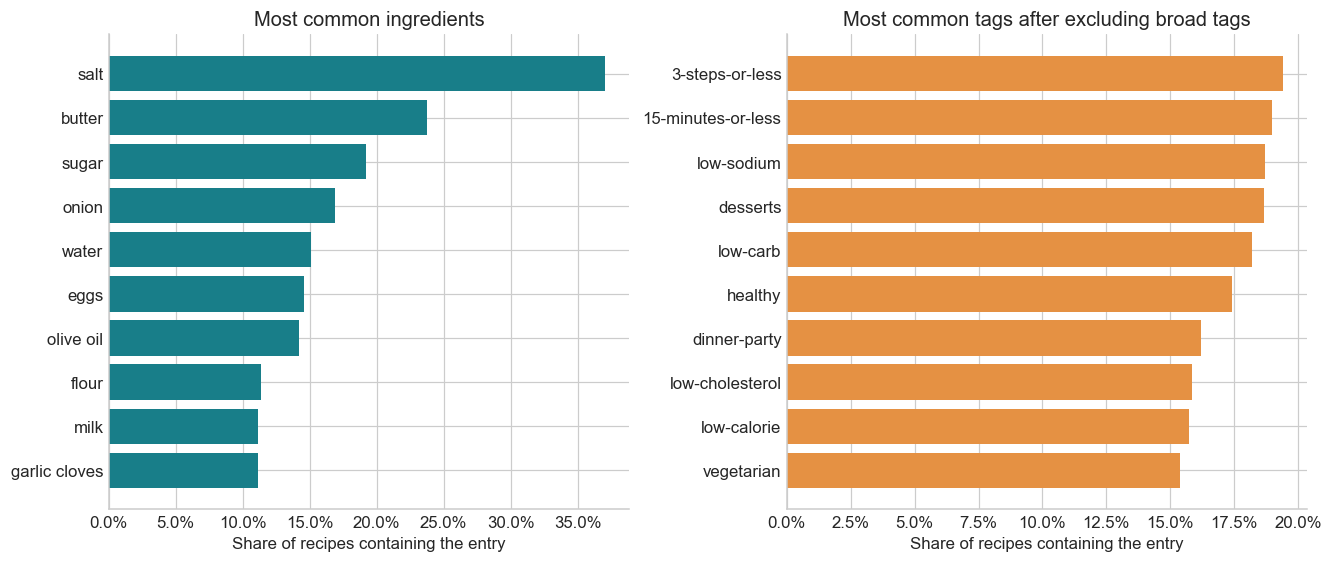

**Results.** **99.95% of recipes have ingredients and tags**.
The median recipe has **9 ingredients**
and **17 tags**. The catalog contains
**14,941 ingredient phrases** and
**551 tags**.

The **19 tags on at least 20% of recipes** include broad labels such as
`preparation` and `course`. Ingredient phrases found in only one recipe make up
**23.7% of distinct phrases**,
but only **0.17%
of ingredient entries** overall.

**Implications for our recommendation system.** Ingredients and tags provide widely
available content features. Giving common entries less weight could help distinguish
recipes. Availability alone does not show that these features produce useful recommendations.

In [19]:
metadata_rows = []
frequency_tables = {}
for label, column, frequency in [('Ingredients', 'ingredients', ingredient_frequency),
                                  ('Tags', 'tags', tag_frequency)]:
    lengths = recipes[column + '_set'].map(len)
    counts = pd.Series(frequency, name='recipes').sort_values(ascending=False)
    frequency_tables[label] = counts
    metadata_rows.append({
        'field': label, 'nonempty valid %': recipes[column + '_available'].mean() * 100,
        'tokens p10': lengths.quantile(.10), 'tokens median': lengths.median(),
        'tokens p90': lengths.quantile(.90), 'tokens max': lengths.max(),
        'vocabulary': len(counts), 'singleton vocabulary %': counts.eq(1).mean() * 100,
        'token occurrences in singleton vocabulary %': counts.loc[counts.eq(1)].sum() / counts.sum() * 100,
        'tokens on >=20% recipes': counts.ge(n_recipes * .2).sum(),
    })
metadata_table = pd.DataFrame(metadata_rows).set_index('field')
display(metadata_table[[
    'nonempty valid %', 'tokens median', 'tokens p90', 'vocabulary', 'singleton vocabulary %'
]].rename(columns={
    'nonempty valid %': 'Available (%)', 'tokens median': 'Median entries per recipe',
    'tokens p90': '90th percentile entries', 'vocabulary': 'Distinct entries',
    'singleton vocabulary %': 'Entries found in one recipe (%)',
}))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_ingredients = frequency_tables['Ingredients'].head(10).sort_values()
specific_frequency = frequency_tables['Tags'].drop(index=list(broad_tags)).head(10).sort_values()
for ax, counts, title, color in [
    (axes[0], top_ingredients, 'Most common ingredients', COLORS[0]),
    (axes[1], specific_frequency, 'Most common tags after excluding broad tags', COLORS[1]),
]:
    ax.barh(counts.index, counts / n_recipes, color=color)
    ax.set(xlabel='Share of recipes containing the entry', title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.show()

both_content = recipes[['ingredients_available', 'tags_available']].all(axis=1)
display(Markdown(f"""**Results.** **{both_content.mean():.2%} of recipes have ingredients and tags**.
The median recipe has **{metadata_table.loc['Ingredients', 'tokens median']:.0f} ingredients**
and **{metadata_table.loc['Tags', 'tokens median']:.0f} tags**. The catalog contains
**{int(metadata_table.loc['Ingredients', 'vocabulary']):,} ingredient phrases** and
**{int(metadata_table.loc['Tags', 'vocabulary']):,} tags**.

The **{len(broad_tags)} tags on at least 20% of recipes** include broad labels such as
`preparation` and `course`. Ingredient phrases found in only one recipe make up
**{metadata_table.loc['Ingredients', 'singleton vocabulary %']:.1f}% of distinct phrases**,
but only **{metadata_table.loc['Ingredients', 'token occurrences in singleton vocabulary %']:.2f}%
of ingredient entries** overall.

**Implications for our recommendation system.** Ingredients and tags provide widely
available content features. Giving common entries less weight could help distinguish
recipes. Availability alone does not show that these features produce useful recommendations."""))


## 10. Why evaluate recommendations in time order?

**Research question.** How do review activity and available histories change over time?

**Analysis.** Count date-consistent reviews, active reviewers, reviewed recipes, and
submissions by year. Also examine recipe age at review and users with reviews on
multiple days. The final year ends on December 20, 2018, so it is incomplete;
these trends do not explain the causes of changing activity.


,Reviews per active reviewer,First-time reviewers (%)
year,,
2005,5.75,69.53
2008,5.12,66.63
2011,3.31,58.67
2014,1.92,72.74
2017,1.24,89.81
2018,1.19,89.80


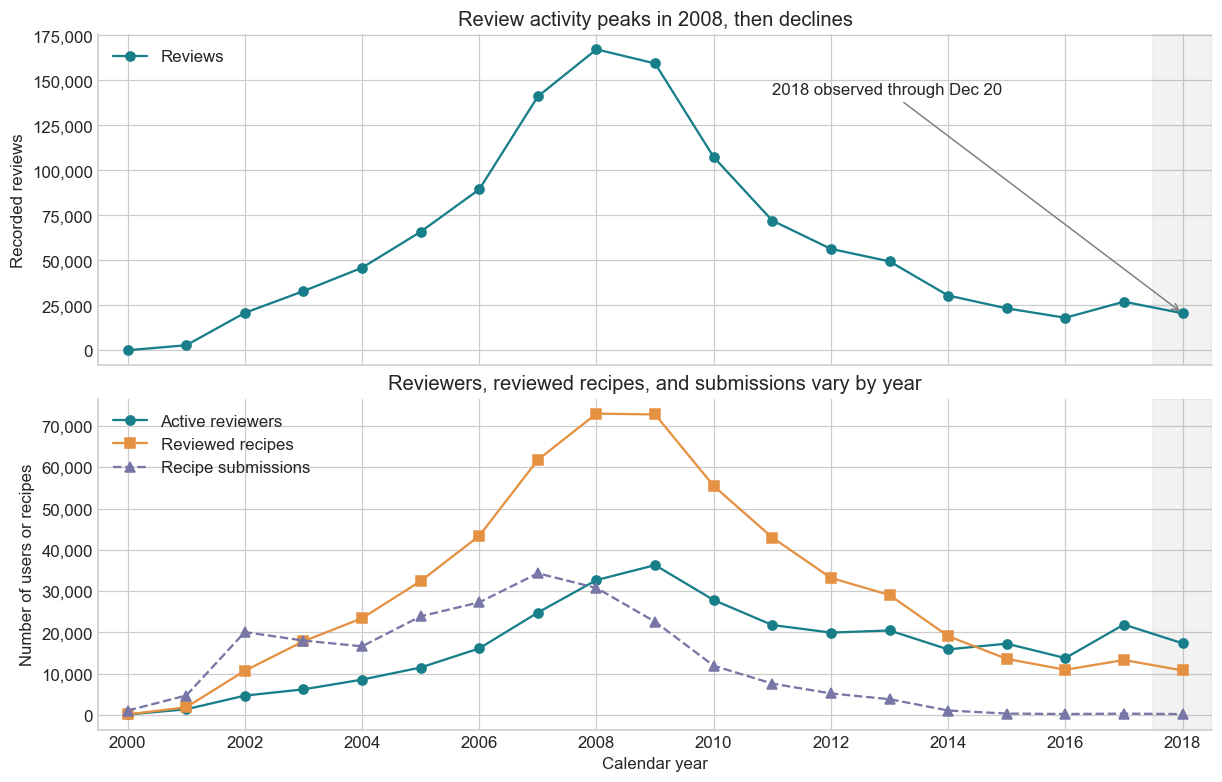

**Results.** Reviews peak in **2008 at 167,265**, compared with
**27,062** in 2017, the last full year. Reviews per active
reviewer fall from **5.1** in 2008 to
**1.2** in 2017. Recipes are a median
**1,079 days old** when reviewed. Only **24.2%
of users** in the valid timeline review on multiple days.

**Implications for our recommendation system.** Later evaluation must build popularity
and user profiles from earlier reviews, include only already submitted recipes, and
keep same-day reviews together. Random splits could let future preferences or reviews
inform earlier recommendations. Report results by prior user and recipe history.
The final metadata snapshot has no edit history, so historical content availability
cannot be verified fully. We leave evaluation dates and train/test splits undecided.

In [20]:
annual = temporal.assign(year=temporal.date.dt.year).groupby('year').agg(
    reviews=('recipe_id', 'size'), users=('user_id', 'nunique'),
    reviewed_recipes=('recipe_id', 'nunique'))
annual['submitted_recipes'] = recipes.groupby(recipes.submitted.dt.year).size().reindex(annual.index, fill_value=0)
annual['first_observed_users'] = first_user_day.dt.year.value_counts().reindex(annual.index, fill_value=0)
annual['reviews_per_active_user'] = annual.reviews / annual.users
activity_summary = pd.DataFrame({
    'Reviews per active reviewer': annual.reviews_per_active_user,
    'First-time reviewers (%)': annual.first_observed_users / annual.users * 100,
})
display(activity_summary.loc[[2005, 2008, 2011, 2014, 2017, 2018]])

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(annual.index, annual.reviews, 'o-', color=COLORS[0], label='Reviews')
axes[0].set(ylabel='Recorded reviews', title='Review activity peaks in 2008, then declines')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[0].legend()
axes[1].plot(annual.index, annual.users, 'o-', color=COLORS[0], label='Active reviewers')
axes[1].plot(annual.index, annual.reviewed_recipes, 's-', color=COLORS[1], label='Reviewed recipes')
axes[1].plot(annual.index, annual.submitted_recipes, '^--', color=COLORS[2], label='Recipe submissions')
axes[1].set(xlabel='Calendar year', ylabel='Number of users or recipes', xticks=annual.index[::2],
            title='Reviewers, reviewed recipes, and submissions vary by year')
axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].legend()
for ax in axes:
    ax.axvspan(2017.5, 2018.5, color='gray', alpha=.10)
    ax.set_xlim(1999.5, 2018.5)
axes[0].annotate('2018 observed through ' + temporal.date.max().strftime('%b %d'),
                 xy=(2018, annual.loc[2018, 'reviews']), xytext=(2011, annual.reviews.max() * .85),
                 arrowprops={'arrowstyle': '->', 'color': 'gray'})
plt.show()

recipe_age_days = (temporal.date - temporal.recipe_id.map(recipe_submitted)).dt.days
temporal_users = temporal.groupby('user_id').date.agg(['min', 'max'])
multi_day_share = temporal_users['min'].lt(temporal_users['max']).mean()
peak_year = int(annual.reviews.idxmax())
display(Markdown(f"""**Results.** Reviews peak in **{peak_year} at {annual.reviews.max():,}**, compared with
**{annual.loc[2017, 'reviews']:,}** in 2017, the last full year. Reviews per active
reviewer fall from **{annual.loc[2008, 'reviews_per_active_user']:.1f}** in 2008 to
**{annual.loc[2017, 'reviews_per_active_user']:.1f}** in 2017. Recipes are a median
**{recipe_age_days.median():,.0f} days old** when reviewed. Only **{multi_day_share:.1%}
of users** in the valid timeline review on multiple days.

**Implications for our recommendation system.** Later evaluation must build popularity
and user profiles from earlier reviews, include only already submitted recipes, and
keep same-day reviews together. Random splits could let future preferences or reviews
inform earlier recommendations. Report results by prior user and recipe history.
The final metadata snapshot has no edit history, so historical content availability
cannot be verified fully. We leave evaluation dates and train/test splits undecided."""))


## Summary: what should our recommendation system compare?

The persistence and historical coverage experiments show modest content signals among
repeat reviewers. They motivate the following approaches, whose recommendation quality
still needs chronological evaluation.


In [21]:
display(Markdown(f"""- **Popularity-based:** use earlier review counts as a baseline and a fallback for
  users with no or insufficient history; the top 10% of recipes receive **{top10_share:.1%}** of reviews.
- **Collaborative filtering:** use shared review patterns where histories support them;
  sparsity and the **{single_user_share:.1%} of users with one review** limit its reach.
- **Content-based:** persistent ingredient/tag overlap and extra historical coverage suggest
  personalization potential. Twenty earlier recipes cover **{coverage_ingredients.same:.1%}**
  of later ingredients versus **{coverage_ingredients.random:.1%}** for other users.
  The coverage experiment's eligible group is only **{len(coverage_eligible) / n_users:.2%} of users**.
- **Hybrid:** combine these signals, using content for recipes without prior reviews
  and popularity when user history is insufficient. Newly submitted recipes and older
  unreviewed recipes both lack review history, but differ in when they become available.

**Higher overlap does not guarantee accurate recommendations.** These analyses describe
recorded reviews; they do not establish which approach recommends best."""))

# Verify that counts, similarities, and cold-start calculations agree.
assert recipe_counts.sum() == n_reviews == user_counts.sum()
assert rating_counts.sum() == n_reviews
assert len(temporal) == annual.reviews.sum()
assert np.isfinite(similarity_table.to_numpy()).all()
assert len(pair_users) == len(sampled_users)
assert pairs.groupby('user_id').size().between(1, 5).all()
assert not pairs.duplicated(['user_id', 'a', 'b']).any()
assert (pairs.a != pairs.b).all()
assert recipe_age_days.ge(0).all()
assert all(0 <= values.min() <= values.max() <= 1
           for conditions in similarity_users.values() for values in conditions.values())
assert cold_table['cold recipe before review day %'].le(cold_table['cold recipe at start %'] + 1e-9).all()
assert np.isfinite(lag_summary.to_numpy()).all()
assert np.isfinite(coverage_summary.to_numpy()).all()

print('EDA consistency checks passed. No predictive models fitted; no train/test split created.')


- **Popularity-based:** use earlier review counts as a baseline and a fallback for
  users with no or insufficient history; the top 10% of recipes receive **54.8%** of reviews.
- **Collaborative filtering:** use shared review patterns where histories support them;
  sparsity and the **73.4% of users with one review** limit its reach.
- **Content-based:** persistent ingredient/tag overlap and extra historical coverage suggest
  personalization potential. Twenty earlier recipes cover **47.6%**
  of later ingredients versus **42.3%** for other users.
  The coverage experiment's eligible group is only **2.79% of users**.
- **Hybrid:** combine these signals, using content for recipes without prior reviews
  and popularity when user history is insufficient. Newly submitted recipes and older
  unreviewed recipes both lack review history, but differ in when they become available.

**Higher overlap does not guarantee accurate recommendations.** These analyses describe
recorded reviews; they do not establish which approach recommends best.

EDA consistency checks passed. No predictive models fitted; no train/test split created.
